## Librerias

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split


import nltk

from collections import Counter
from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer

from gensim.models import Word2Vec

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

Importamos las librerias necesarias para cargar, analizar, visualizar y posteriormente dividir el conjunto de datos

## Semilla Aleatoria

Se define una semilla fija para garantizar que los procesos que involucren aleatoriedad sean reproducibles 

In [17]:
SEED=42
np.random.seed(SEED)


Al fijar la semilla en 42 garantizamos reproducibilidad, es decir, que otra persona pueda ejecutar el nootebook y obtener exactamente la misma division y de esta forma evitar resultados como Q100 -> train y en otra ejecucion Q100 -> validation 

## Carga de datos

In [18]:
df = pd.read_csv(
    "WikiQA_Tarea3.tsv",
    sep="\t"
)

Como el archivo no es realmente un csv separado por comnas si no un tsv, utilizamos sep="\t" para indicarle a pandas que cada tabulacion representa una nueva columna 

## Revision inicial de datos

Se revisan las dimensiones del conjunto, los nombres de las columnas, los tipos de datos y los primeros registros

In [19]:
print(df.shape)
# obtenemos el tamaño del dataset
print(df.columns.tolist())
# obtenemos los nombres de las columnas
print(df.dtypes)
# obtenemos los tipos de datos de cada columna
print(df.head())
# obtenemos las primeras 5 filas del dataset

(29196, 7)
['QuestionID', 'Question', 'DocumentID', 'DocumentTitle', 'SentenceID', 'Sentence', 'Label']
QuestionID         str
Question           str
DocumentID         str
DocumentTitle      str
SentenceID         str
Sentence           str
Label            int64
dtype: object
  QuestionID                     Question DocumentID  DocumentTitle  \
0       Q428  how much of US 75 is 4 lane       D423  U.S. Route 75   
1       Q428  how much of US 75 is 4 lane       D423  U.S. Route 75   
2       Q428  how much of US 75 is 4 lane       D423  U.S. Route 75   
3       Q428  how much of US 75 is 4 lane       D423  U.S. Route 75   
4       Q428  how much of US 75 is 4 lane       D423  U.S. Route 75   

  SentenceID                                           Sentence  Label  
0     D423-0      U.S. Route 75 is a north–south U.S. Highway .      0  
1     D423-1  The highway's northern terminus is in Kittson ...      0  
2     D423-2  Its southern terminus is at Interstate 30 and ...      0  
3 

El objetivo es comprobar que el archivo fue cargado correctamente y entender su estructura antes de realizar cualquier transformación.


## Cantidad de registros y preguntas 

Se calcula la cantidad total de registros y la cantidad de preguntas diferentes presentes en el dataset.

Debido a que una pregunta puede estar asociada a múltiples oraciones candidatas, ambas cantidades son diferentes.

In [20]:
print("Largo del data ser:", len(df))
# obtenemos el número de filas del dataset
print("Cantidad de preguntas únicas:",df["QuestionID"].nunique())
# obtenemos el número de preguntas únicas, es decir el número de filas que tienen un valor único en la columna "QuestionID"
print("Cantidad de documentos unicos:", df["DocumentID"].nunique())
# obtenemos el número de documentos únicos, es decir el número de filas que tienen un valor único en la columna "DocumentID"

Largo del data ser: 29196
Cantidad de preguntas únicas: 3043
Cantidad de documentos unicos: 2808


## Datos faltantes

Se verifica si existen valores ausentes en alguna de las columnas del dataset

In [21]:
datos_faltantes=df.isnull().sum()

print("La cantidad de datos faltantes es de:", datos_faltantes)

La cantidad de datos faltantes es de: QuestionID       0
Question         0
DocumentID       0
DocumentTitle    0
SentenceID       0
Sentence         0
Label            0
dtype: int64


Del resultado podes concluir que no existen datos faltantes

## Filas duplicadas

In [22]:
duplicados_completos = df.duplicated().sum()

duplicados_id = df.duplicated(
    subset=["QuestionID", "SentenceID"] # trabajamos con el id de la pregunta
).sum()

print("Filas duplicadas:", duplicados_completos)
print("Duplicados QuestionID-SentenceID:", duplicados_id)   

Filas duplicadas: 0
Duplicados QuestionID-SentenceID: 0


No existen registros completamente repetidos ni identificadores de oración duplicados dentro de una misma pregunta. 

Por lo que no es necesario eliminar columnas.

## Oraciones repetidas

Además de revisar filas completamente duplicadas, se comprueba si una misma pregunta contiene más de una candidata con exactamente el mismo texto.

In [23]:
duplicados_texto = df.duplicated(
    subset=["QuestionID", "Sentence"] # aqui no se trabaja con el id de la pregunta, sino con el texto de la pregunta
).sum()

print(
    "Candidatas textualmente repetidas:",
    duplicados_texto
)

Candidatas textualmente repetidas: 8


Existen 8 casos donde una pregunta posee candidatas cuyo texto es idéntico y apesar de esto no las eliminaremos, aunque se identificaron algunas oraciones textualmente repetidas dentro de una misma pregunta, estas no fueron eliminadas. 

Se debe a que corresponden a registros distintos del dataset original y poseen diferentes identificadores de oración. Además, su presencia no representa un impedimento significativo para las etapas posteriores de entrenamiento, recuperación y evaluación, ya que el sistema trabajará con las candidatas asociadas a cada `QuestionID` tal como fueron entregadas en el conjunto de datos.

## Cantidad de candidatas por pregunta

In [24]:
candidatas_por_pregunta = (
    df.groupby("QuestionID").size() # las agrupamos por el id de la pregunta, eso es lo que hace .groupby() 
)

display(
    candidatas_por_pregunta.describe()
) # con display() mostramos un resumen estadístico de la cantidad de candidatas por pregunta, es decir, cuántas filas hay por cada pregunta única

count    3043.000000
mean        9.594479
std         6.254770
min         1.000000
25%         5.000000
50%         8.000000
75%        13.000000
max        30.000000
dtype: float64

Se agrupan los registros de acuerdo con QuestionID para determinar cuántas oraciones candidatas posee cada pregunta.

Esto permite entender la cantidad de alternativas entre las cuales posteriormente tendrá que seleccionar el sistema de recuperación.

## Distribucion de candidatas

Se visualiza la cantidad de oraciones candidatas por pregunta mediante un histograma.

El gráfico permite observar de manera más clara cómo se distribuyen las preguntas según la cantidad de candidatas disponibles.

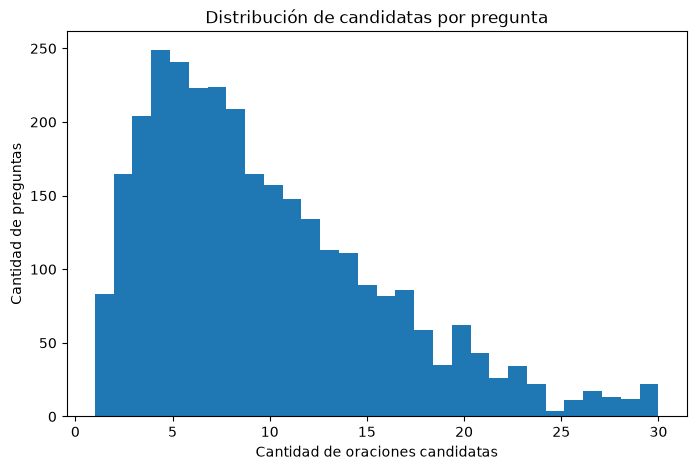

In [25]:
plt.figure(figsize=(8, 5))

plt.hist(
    candidatas_por_pregunta,
    bins=30
)

plt.xlabel(
    "Cantidad de oraciones candidatas"
)

plt.ylabel(
    "Cantidad de preguntas"
)

plt.title(
    "Distribución de candidatas por pregunta"
)

plt.show()

La distribución está sesgada hacia la derecha: la mayoría de las preguntas tiene una cantidad relativamente baja o moderada de oraciones candidatas, mientras que son pocas las preguntas que tienen una cantidad muy alta.

La mayor concentración parece estar aproximadamente entre 4 y 10 candidatas por pregunta, y el máximo llega cerca de 30 candidatas.

## Distribucion del Label 

Se analiza la frecuencia de las clases 0 y 1.

Esto permite conocer qué proporción de las oraciones candidatas realmente responde correctamente a su pregunta.

In [26]:
distribucion_label = (
    df["Label"]
    .value_counts()
    .sort_index()
)

porcentaje_label = (
    df["Label"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("Cantidad:")
print(distribucion_label)

print("\nPorcentaje:")
print(porcentaje_label)

Cantidad:
Label
0    27726
1     1470
Name: count, dtype: int64

Porcentaje:
Label
0    94.965064
1     5.034936
Name: proportion, dtype: float64


Existe un fuerte desbalance a nivel de candidatas.

La gran mayoría de las oraciones, no responde la pregunta, mientras que solamente una pequeña proporción corresponde a respuestas correctas.

## Grafico de Label

Se representa gráficamente la cantidad de registros correspondientes a cada clase.

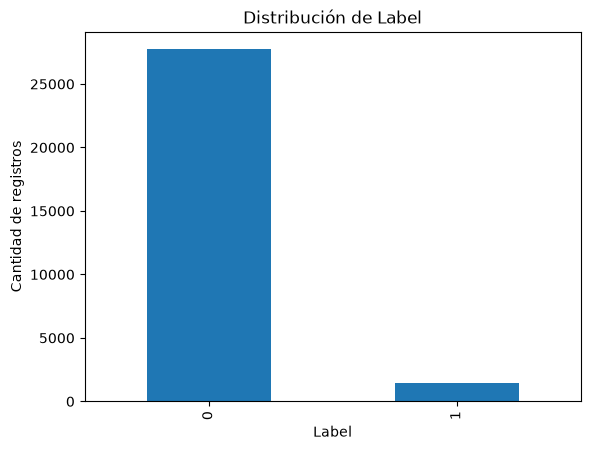

In [27]:
distribucion_label.plot(
    kind="bar"
)

plt.xlabel("Label")
plt.ylabel("Cantidad de registros")
plt.title("Distribución de Label")

plt.show()

## Preguntas con y sin respuestas correctas

El análisis anterior considera cada candidata de manera individual.

Sin embargo, también es necesario determinar si cada pregunta posee al menos una candidata correcta.

Para esto se agrupan los registros por QuestionID y se crea la variable has_answer.

In [28]:
question_info = (
    df.groupby("QuestionID")
      .agg(
          has_answer=("Label", "max")
      )
      .reset_index()
)

display(question_info.head()) # lo que hace es agrupar el dataframe por el id de la pregunta y luego aplicar la función max() a la columna "Label" para obtener si hay al menos una respuesta correcta para cada pregunta. Luego, se reinicia el índice del dataframe resultante para que tenga un índice secuencial en lugar del índice original de las preguntas.

,QuestionID,has_answer
0,Q0,1
1,Q1,1
2,Q10,0
3,Q100,1
4,Q1000,0


## Cantidad de preguntas con respuestas

Se calcula la cantidad de preguntas que poseen al menos una candidata correcta y la cantidad de preguntas para las cuales ninguna candidata constituye una respuesta.

In [29]:
distribucion_respuesta = (
    question_info["has_answer"]
    .value_counts()
    .sort_index()
)

print(distribucion_respuesta)

has_answer
0    1804
1    1239
Name: count, dtype: int64


Esto es diferente de la distribución de Label.

Label describe candidatas individuales.

has_answer describe preguntas completas.

Esta distinción será esencial para realizar correctamente la división de los datos.

## Resumen del análisis exploratorio

In [30]:
resumen = pd.DataFrame({
    "Métrica": [
        "Registros",
        "Preguntas",
        "Documentos",
        "Label 0",
        "Label 1",
        "Preguntas con respuesta",
        "Preguntas sin respuesta",
        "Valores faltantes",
        "Filas duplicadas"
    ],
    "Valor": [
        len(df),
        df["QuestionID"].nunique(),
        df["DocumentID"].nunique(),
        (df["Label"] == 0).sum(),
        (df["Label"] == 1).sum(),
        (
            question_info["has_answer"] == 1
        ).sum(),
        (
            question_info["has_answer"] == 0
        ).sum(),
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

display(resumen)

,Métrica,Valor
0,Registros,29196
1,Preguntas,3043
2,Documentos,2808
3,Label 0,27726
4,Label 1,1470
5,Preguntas con respuesta,1239
6,Preguntas sin respuesta,1804
7,Valores faltantes,0
8,Filas duplicadas,0


## Division de los datos

La división se realiza a nivel de QuestionID y no a nivel de filas.

De esta manera, todas las oraciones candidatas correspondientes a una misma pregunta permanecen dentro del mismo conjunto.

Esta condición evita que información relacionada con una pregunta utilizada durante entrenamiento aparezca posteriormente en validación o prueba.

El enunciado exige explícitamente realizar la división de esta manera.     tarea3-IA v3

## Primera division, train y conjunto temporal

La división debe realizarse a nivel de QuestionID, porque todas las candidatas de una misma pregunta deben permanecer juntas.     tarea3-IA v3

No dividimos directamente las filas de df, porque podríamos tener:
Q10 → candidata 1 → Train
Q10 → candidata 2 → Validation

Eso produciría data leakage, ya que la misma pregunta aparecería en más de un conjunto.

In [31]:
train_questions, temp_questions = train_test_split(
    question_info,
    test_size=0.30,
    random_state=SEED,
    stratify=question_info["has_answer"] # lo que hace stratify es asegurarse de que la proporción de preguntas con y sin respuesta se mantenga en ambos conjuntos, es decir, que la distribución de la variable "has_answer" sea similar en el conjunto de entrenamiento y en el conjunto temporal. Esto es importante para evitar sesgos en el modelo y garantizar que se entrene con una representación adecuada de ambas clases.
)

## Division validation/test

Ahora el 30% que dejamos temporalmente se divide en dos partes iguales.

Como: 30% x 0.5 = 15%

obtenemos finalmente:
70% Train
15% Validation
15% Test

In [32]:
validation_questions, test_questions = train_test_split(
    temp_questions,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_questions["has_answer"]
) # generamos un conjunto de validación y un conjunto de prueba a partir del conjunto temporal, manteniendo la proporción de preguntas con y sin respuesta en ambos conjuntos.

## Recuperamos filas originales

Hasta este momento solamente hemos separado los QuestionID.

Ahora necesitamos recuperar todas las oraciones candidatas pertenecientes a cada pregunta.

In [33]:
train_df = df[
    df["QuestionID"].isin(train_questions["QuestionID"])
].copy()

validation_df = df[
    df["QuestionID"].isin(validation_questions["QuestionID"])
].copy()

test_df = df[
    df["QuestionID"].isin(test_questions["QuestionID"])
].copy()

# .isin lo que hace es verificar si los valores de la columna "QuestionID" del dataframe df están presentes en la columna "QuestionID" del dataframe train_questions, validation_questions o test_questions, respectivamente. Esto nos permite filtrar el dataframe original df y crear tres nuevos dataframes (train_df, validation_df y test_df) que contienen solo las filas correspondientes a las preguntas seleccionadas para cada conjunto.

## Resumen de los conjuntos

In [34]:
split_summary = pd.DataFrame({
    "Conjunto": ["Train", "Validation", "Test"],

    "Registros": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],

    "Preguntas": [
        train_df["QuestionID"].nunique(),
        validation_df["QuestionID"].nunique(),
        test_df["QuestionID"].nunique()
    ],

    "Con respuesta": [
        (train_questions["has_answer"] == 1).sum(),
        (validation_questions["has_answer"] == 1).sum(),
        (test_questions["has_answer"] == 1).sum()
    ],

    "Sin respuesta": [
        (train_questions["has_answer"] == 0).sum(),
        (validation_questions["has_answer"] == 0).sum(),
        (test_questions["has_answer"] == 0).sum()
    ]
})

display(split_summary)

,Conjunto,Registros,Preguntas,Con respuesta,Sin respuesta
0,Train,20216,2130,867,1263
1,Validation,4476,456,186,270
2,Test,4504,457,186,271


Esta tabla nos permite comprobar rápidamente:
- cuántos registros quedaron en cada conjunto;
- cuántas preguntas hay;
- cuántas tienen respuesta;
- cuántas no tienen respuesta.
No esperamos exactamente 70/15/15 de filas, porque una pregunta puede tener muchas más candidatas que otra.

## Verificamos intersecciones

In [35]:
train_ids = set(train_df["QuestionID"])
validation_ids = set(validation_df["QuestionID"])
test_ids = set(test_df["QuestionID"])

print("Definimos inter como la intersección de los conjuntos de preguntas de train, validation y test")

print(
    "Train inter Validation:",
    len(train_ids & validation_ids)
)

print(
    "Train inter Test:",
    len(train_ids & test_ids)
)

print(
    "Validation inter Test:",
    len(validation_ids & test_ids)
)

Definimos inter como la intersección de los conjuntos de preguntas de train, validation y test
Train inter Validation: 0
Train inter Test: 0
Validation inter Test: 0


Podemos concluir que no existe contamincacion entre conjuntos

## Procesamiento lingüístico 

En el apartado de librerias necesarias en el apartado de librerias y descargamos los recursos necesarios

In [36]:
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("averaged_perceptron_tagger", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

True

## Tratamiento de puntacion 

No queremos que signos como:
.
,
?
!

se conviertan en palabras dentro del vocabulario Word2Vec.

Por eso eliminaremos tokens que no contengan ningún carácter alfanumérico.

In [37]:
def remove_punctuation_tokens(tokens):

    return [
        token
        for token in tokens
        if any(char.isalnum() for char in token) 
    ] # lo que hace es primero preguntar si algún caracter del token es alfanumérico, es decir, si contiene letras o números. 
#Si el token contiene al menos un caracter alfanumérico, se mantiene en la lista de tokens resultante. De lo contrario, se descarta. 
#Esto permite eliminar tokens que consisten únicamente en signos de puntuación u otros caracteres no alfanuméricos.
#Se logra usando la función any() que devuelve True si al menos un elemento del iterable es verdadero, 
#y la función isalnum() que verifica si un caracter es alfanumérico.

## Stopwords

Vamos a conservarlas.

En muchos problemas de NLP se eliminan palabras como:
the, a, of, is, in, porque aparecen con mucha frecuencia.

Sin embargo, aquí entrenaremos Word2Vec, que aprende el significado de las palabras observando las palabras que aparecen alrededor.

Eliminar stopwords podría alterar artificialmente esas ventanas de contexto.

Además, estamos trabajando con preguntas:
who
what
where
when
how

y la estructura gramatical puede ser útil para entender el contexto.

Por estas razones, en este pipeline se decidió conservar las stopwords.

## Analisis POS

El análisis POS debe realizarse antes de modificar morfológicamente las palabras.

In [38]:
def basic_tokens(text):

    text = text.lower()

    tokens = word_tokenize(text)

    tokens = remove_punctuation_tokens(tokens)

    return tokens

Para eso primero creamos una funcion que: 
1) convierte a minúsculas
2) tokeniza
3) elimina puntuación

## Construir POS

Una pregunta aparece repetida tantas veces como candidatas tenga.

Por ejemplo, si Q1 tiene 15 candidatas, su texto aparece 15 veces.

Si utilizáramos todas esas filas, estaríamos contando artificialmente esa pregunta 15 veces.

Por eso tomamos cada pregunta una sola vez.

In [39]:
unique_train_questions = (
    train_df
    .drop_duplicates("QuestionID") # con drop_duplicates() eliminamos las filas duplicadas en base a la columna "QuestionID", 
    #es decir, nos quedamos con una sola fila por cada pregunta única en el conjunto de entrenamiento.
    ["Question"]
)

texts_for_pos = (
    unique_train_questions.tolist()
    +
    train_df["Sentence"].tolist()
)

## Contamos las etiquetas POS

In [40]:
pos_counter = Counter()

for text in texts_for_pos:

    tokens = basic_tokens(text)

    tagged_tokens = pos_tag(tokens)

    pos_counter.update(
        tag
        for _, tag in tagged_tokens
    )

print(
    pos_counter.most_common(15)
)

[('NN', 111502), ('IN', 62356), ('JJ', 52487), ('DT', 51779), ('NNS', 35044), ('CC', 18035), ('CD', 15428), ('VBN', 15409), ('RB', 13618), ('VBZ', 13226), ('VBD', 13040), ('TO', 8322), ('VB', 8099), ('VBP', 7555), ('VBG', 7227)]


## Simplificar categorias POS

Las etiquetas de Penn Treebank son bastante específicas.

Por ejemplo:
NN
NNS
NNP
NNPS

son distintos tipos de sustantivos.

Para facilitar la interpretación del análisis podemos agruparlos en categorías generales.

In [41]:
def simplify_pos(tag):

    if tag.startswith("N"):
        return "NOUN"

    if tag.startswith("V"):
        return "VERB"

    if tag.startswith("J"):
        return "ADJECTIVE"

    if tag.startswith("R"):
        return "ADVERB"

    return "OTHER"

Ahora las agrupamos

In [42]:
simplified_pos = Counter()

for tag, count in pos_counter.items():

    simplified_pos[
        simplify_pos(tag)
    ] += count

Y las visualizamos en una tabla

In [43]:
pos_df = pd.DataFrame(
    simplified_pos.items(),
    columns=[
        "POS",
        "Frecuencia"
    ]
)

pos_df = pos_df.sort_values(
    "Frecuencia",
    ascending=False
)

display(pos_df)

,POS,Frecuencia
0,OTHER,177474
2,NOUN,146873
1,VERB,64556
3,ADJECTIVE,55400
4,ADVERB,15260


Una vez agrupadas las etiquetas POS, se suman las frecuencias correspondientes a cada categoría general. De esta manera, por ejemplo, todas las variantes de sustantivos contribuyen al total de NOUN y todas las variantes verbales al total de VERB.

Posteriormente, los resultados se convierten en un DataFrame con dos columnas: la categoría gramatical (POS) y su frecuencia de aparición. Esta representación permite organizar los resultados de forma clara y facilita tanto su comparación como su posterior visualización

## Graficamos POS

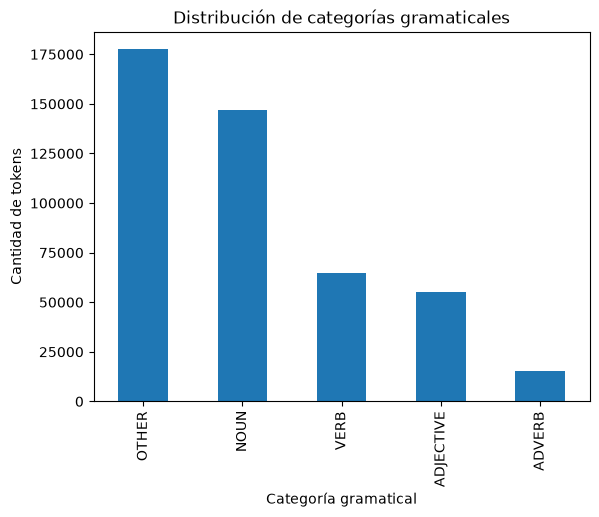

In [44]:
pos_df.plot(
    x="POS",
    y="Frecuencia",
    kind="bar",
    legend=False
)

plt.xlabel("Categoría gramatical")
plt.ylabel("Cantidad de tokens")
plt.title(
    "Distribución de categorías gramaticales"
)

plt.show()

El gráfico permite visualizar rápidamente qué tipos de palabras predominan en el corpus.

No estamos utilizando estos valores para entrenar directamente Word2Vec; el objetivo es caracterizar lingüísticamente el dataset.

## Lemmatizacion

Hasta este punto ya normalizamos el texto, lo tokenizamos y analizamos sus categorías gramaticales. Ahora necesitamos reducir distintas formas de una misma palabra a una representación común.

Por ejemplo:
cars → car
studies → study
written → write

La idea es evitar que Word2Vec considere innecesariamente estas formas como palabras completamente independientes cuando representan conceptos muy relacionados.

¿Por qué lematización y no stemming?
El stemming simplemente recorta palabras mediante reglas y puede producir resultados que no corresponden a palabras reales:
studies → studi
studying → studi

En cambio, la lematización intenta obtener una forma léxica válida:
studies → study
studying → study

Esto resulta más conveniente en nuestro caso porque posteriormente utilizaremos las palabras para:
- entrenar Word2Vec;
- analizar palabras similares;
- interpretar los embeddings.
Trabajar con palabras reconocibles facilita mucho ese análisis cualitativo.

Además, la tarea exige escoger entre lematización y stemming y justificar la decisión.

## Creamos Lemmatizacion 

In [45]:
lemmatizer = WordNetLemmatizer() 
#wordnet lemmatizer es un algoritmo que reduce las palabras a su forma base o raíz, conocida como lema.

## Conversion de etiquetas POS para WordNet

NLTK entrega etiquetas como:
NN
VBD
JJ
RB

pero WordNetLemmatizer espera categorías diferentes:
n → noun
v → verb
a → adjective
r → adverb

Por eso necesitamos convertirlas.

In [46]:
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return "a"

    if tag.startswith("V"):
        return "v"

    if tag.startswith("N"):
        return "n"

    if tag.startswith("R"):
        return "r"

    return "n"

## Pipeline completo de procesamiento

Es importante utilizar una sola función porque el enunciado exige que el mismo proceso de preprocesamiento sea aplicado a:
Train
Validation
Test

    tarea3-IA v3

Esto evita que cada conjunto termine siendo procesado de manera diferente.

Nuestro pipeline seguirá este orden:
Texto original -> Minúsculas -> Tokenización -> Eliminación de puntuación -> POS tagging -> Lematización -> Tokens finales

Las stopwords se conservarán, tal como decidimos anteriormente.

In [47]:
def preprocess_text(text):

    #  Normalización a minúsculas
    text = text.lower()

    # Tokenización
    tokens = word_tokenize(text)

    #  Eliminación de tokens de puntuación
    tokens = remove_punctuation_tokens(tokens)

    #  Obtención de categorías gramaticales
    tagged_tokens = pos_tag(tokens)

    #  Lemmatización considerando POS
    lemmas = [
        lemmatizer.lemmatize(
            token,
            get_wordnet_pos(tag)
        )
        for token, tag in tagged_tokens
    ]

    return lemmas

## Probamos el procesamiento

In [48]:
example = train_df.iloc[0]["Question"]

print("Texto original:")
print(example)

print("\nTexto procesado:")
print(preprocess_text(example))

Texto original:
what does am and pm stand for

Texto procesado:
['what', 'do', 'be', 'and', 'pm', 'stand', 'for']


Esto funciona como una comprobación sencilla del pipeline.

Queremos confirmar que:
- el texto queda en minúsculas;
- la puntuación desaparece;
- las palabras quedan correctamente tokenizadas;
- la lematización produce resultados razonables.
Es preferible detectar aquí un problema antes de procesar miles de oraciones y posteriormente entrenar Word2Vec con datos mal preparados.

## Aplicacion a train, validation y test

In [49]:
for dataset in [
    train_df,
    validation_df,
    test_df
]:

    dataset["Question_tokens"] = (
        dataset["Question"]
        .apply(preprocess_text)
    )

    dataset["Sentence_tokens"] = (
        dataset["Sentence"]
        .apply(preprocess_text)
    )

Creamos dos columnas nuevas:
Question_tokens
Sentence_tokens

De esta manera conservamos tanto:
texto original

como:
texto procesado

Esto es importante porque más adelante necesitaremos el texto original para mostrar ejemplos, analizar errores y construir el contexto del RAG.

## Construir el corpus de Word2Vec

Word2Vec debe entrenarse utilizando exclusivamente información perteneciente a Train.     tarea3-IA v3

Nuestro corpus tendrá:
preguntas de Train + oraciones candidatas de Train

Pero las preguntas requieren un tratamiento especial.

Una pregunta aparece repetida tantas veces como candidatas tenga.

Por ejemplo:
Q1 → 15 candidatas

significa que el texto de Q1 aparece 15 veces en train_df.

Si lo agregáramos directamente al corpus, estaríamos aumentando artificialmente su importancia.

Por eso utilizamos cada pregunta solamente una vez.

In [50]:
train_questions_tokens = (
    train_df
    .drop_duplicates("QuestionID")
    ["Question_tokens"]
    .tolist()
)

train_sentences_tokens = (
    train_df["Sentence_tokens"]
    .tolist()
)

train_corpus = (
    train_questions_tokens
    +
    train_sentences_tokens
)

## Definimos las cinco configuraciones

In [51]:
configs = [
    {
        "name": "Exp 1",
        "sg": 0,
        "vector_size": 100,
        "window": 5,
        "min_count": 1,
        "epochs": 10
    },

    {
        "name": "Exp 2",
        "sg": 1,
        "vector_size": 100,
        "window": 5,
        "min_count": 1,
        "epochs": 10
    },

    {
        "name": "Exp 3",
        "sg": 1,
        "vector_size": 200,
        "window": 5,
        "min_count": 1,
        "epochs": 10
    },

    {
        "name": "Exp 4",
        "sg": 1,
        "vector_size": 200,
        "window": 10,
        "min_count": 1,
        "epochs": 10
    },

    {
        "name": "Exp 5",
        "sg": 1,
        "vector_size": 200,
        "window": 10,
        "min_count": 3,
        "epochs": 20
    }
]
# vector_size: tamaño del vector de características que se generará para cada palabra. 
# Un valor más alto puede capturar más información semántica, pero también aumenta el tiempo de entrenamiento y el tamaño del modelo.

# Window: tamaño de la ventana de contexto que se utilizará para entrenar el modelo.

# Min_count: número mínimo de ocurrencias de una palabra para que sea incluida en el vocabulario del modelo.

# epochs: número de iteraciones sobre el corpus de entrenamiento. Un mayor número de épocas puede mejorar la calidad del modelo, 
# ero también aumenta el tiempo de entrenamiento y el riesgo de sobreajuste.

No queremos simplemente entrenar cinco modelos arbitrarios.

La idea es ir modificando parámetros para observar cómo afectan los embeddings y posteriormente el retrieval.
Experimento 1 vs Experimento 2
Exp 1 -> CBOW
Exp 2 -> Skip-gram

El resto de los parámetros se mantiene igual.

Esto permite observar principalmente el efecto de cambiar la arquitectura.
Experimento 2 vs Experimento 3
Cambiar:
vector_size = 100

por:
vector_size = 200

permite analizar si utilizar embeddings con mayor dimensión mejora la representación semántica.
Experimento 3 vs Experimento 4
Se modifica:
window = 5

a:
window = 10

Esto permite observar el efecto de utilizar un contexto más amplio.
Experimento 5
El último modelo introduce dos cambios:
min_count = 3
epochs = 20

Aquí buscamos observar:
- qué ocurre al eliminar palabras muy poco frecuentes;
- qué ocurre al aumentar el entrenamiento.
También será especialmente útil para analizar OOV.

## Entrenamiento del modelo 

In [52]:
models = {}

for config in configs:

    model = Word2Vec(
        sentences=train_corpus,
        vector_size=config["vector_size"],
        window=config["window"],
        min_count=config["min_count"],
        sg=config["sg"],
        epochs=config["epochs"],
        workers=1,
        seed=SEED
    )

    models[
        config["name"]
    ] = model

En lugar de escribir cinco bloques de código prácticamente iguales, almacenamos las configuraciones en una lista y utilizamos un ciclo.

Esto:
- reduce código repetido;
- evita inconsistencias;
- facilita comparar los experimentos;
- permite agregar los resultados posteriormente a una tabla.

## Analizar el tamaño del vocabulario 

El vocabulario representa el conjunto de palabras para las cuales Word2Vec consiguió aprender un embedding.

In [53]:
for name, model in models.items():

    print(
        name,
        "- Tamaño del vocabulario:",
        len(model.wv)
    )

Exp 1 - Tamaño del vocabulario: 28977
Exp 2 - Tamaño del vocabulario: 28977
Exp 3 - Tamaño del vocabulario: 28977
Exp 4 - Tamaño del vocabulario: 28977
Exp 5 - Tamaño del vocabulario: 10835


Este resultado será especialmente útil para observar el efecto de:
min_count

Por ejemplo:
min_count = 1

permite ingresar prácticamente todas las palabras observadas.

En cambio:
min_count = 3

elimina palabras que aparecieron menos de tres veces.

## Analisis de palabras similares

Las métricas de retrieval todavía no nos dicen si los embeddings aprendieron relaciones semánticas razonables.

In [54]:
words_to_analyze = [
    "president",
    "city",
    "country",
    "war",
    "university"
]

Primero seteamos las palabras a analizar

In [55]:
for name, model in models.items():

    print("\n====================")
    print(name)
    print("====================")

    for word in words_to_analyze:

        if word in model.wv:

            similar_words = (
                model.wv.most_similar(
                    word,
                    topn=5
                )
            )

            print(
                f"\nPalabra: {word}"
            )

            for similar_word, similarity in similar_words:

                print(
                    similar_word,
                    round(similarity, 4)
                )

        else:

            print(
                f"\n{word} no está en el vocabulario."
            )


Exp 1

Palabra: president
elect 0.9179
republican 0.9011
presidential 0.8928
senate 0.881
vice 0.8757

Palabra: city
county 0.9085
capital 0.9008
california 0.9005
town 0.9001
locate 0.8914

Palabra: country
continent 0.9057
region 0.8603
economy 0.8346
trans-saharan 0.8157
immigrant 0.8123

Palabra: war
yugoslavia 0.8239
ii 0.8206
unrest 0.8
conflict 0.7957
civil 0.7935

Palabra: university
california 0.9207
pennsylvania 0.9088
head 0.9016
seat 0.9013
texas 0.8943

Exp 2

Palabra: president
vice 0.8478
roosevelt 0.8207
elect 0.8179
franklin 0.7981
nixon 0.7979

Palabra: city
metropolitan 0.8054
jose 0.7789
parish 0.7639
jacksonville 0.7619
orleans 0.7604

Palabra: country
english-speaking 0.6998
diaspora 0.6945
india 0.6891
european 0.685
argentina 0.6832

Palabra: war
outbreak 0.7548
falklands 0.7382
iraq 0.7355
ii 0.7259
acw 0.7234

Palabra: university
college 0.8151
purdue 0.8037
pennsylvania 0.7946
campus 0.7817
graduate 0.7814

Exp 3

Palabra: president
vice 0.8532
roosevelt 0.8

Busca las palabras cuyos embeddings se encuentran más cerca del embedding de la palabra seleccionada.

Los resultados obtenidos con most_similar() muestran que los modelos aprendieron relaciones contextuales razonables entre las palabras. Por ejemplo, president aparece relacionada con términos como vice, elect, obama o biden; war con conflict, fighting, outbreak o nombres de guerras; y university con palabras como college, campus, student y nombres de universidades.

También se observa que una similitud numérica mayor no implica necesariamente una relación de mejor calidad. Algunos modelos presentan valores de similitud altos, pero incluyen términos más generales o menos directamente relacionados. En cambio, las configuraciones Skip-gram producen, en varios casos, asociaciones contextualmente más claras.

Exp 5 mantiene relaciones coherentes a pesar de tener un vocabulario menor y valores de similitud generalmente más bajos. Por lo tanto, el análisis cualitativo muestra que los embeddings capturan relaciones semánticas útiles, aunque deben evaluarse en conjunto con las métricas de recuperación.

## Analisis OOV

Primero creamos el corpus

In [56]:
validation_corpus = (
    validation_df
    .drop_duplicates("QuestionID")
    ["Question_tokens"]
    .tolist()
    +
    validation_df["Sentence_tokens"]
    .tolist()
)

Utilizamos Validation porque queremos evaluar la cobertura del vocabulario aprendido exclusivamente con Train.

Seguimos además el mismo criterio utilizado al construir train_corpus:
- una aparición por pregunta;
- todas las oraciones candidatas.
Así evitamos sobrecontar preguntas simplemente porque poseen muchas candidatas.

## Funcion OOV

In [57]:
def calculate_oov_rate(
    corpus,
    model
):

    total_tokens = 0
    oov_tokens = 0

    for text in corpus:

        for token in text:

            total_tokens += 1

            if token not in model.wv:
                oov_tokens += 1

    if total_tokens == 0:
        return 0.0

    return (
        oov_tokens
        /
        total_tokens
    )

La función cuenta dos cantidades, total_tokens y oov_tokens.

Para cada palabra preguntamos:
if token not in model.wv


Si no existe en el vocabulario aprendido, se considera OOV.

Finalmente calculamos: OOV Rate = OOV/Total

Un OOV alto implica que Word2Vec no puede representar una proporción importante de las palabras observadas en Validation.

## Calculamos el OOV para cada modelo 

In [58]:
oov_results = {}

for name, model in models.items():

    rate = calculate_oov_rate(
        validation_corpus,
        model
    )

    oov_results[name] = rate

    print(
        name,
        "- OOV Rate:",
        round(rate, 4)
    )

Exp 1 - OOV Rate: 0.0493
Exp 2 - OOV Rate: 0.0493
Exp 3 - OOV Rate: 0.0493
Exp 4 - OOV Rate: 0.0493
Exp 5 - OOV Rate: 0.084


Los experimentos 1, 2, 3 y 4 presentan una tasa OOV de aproximadamente 0,0493, lo que significa que cerca del 4,93% de los tokens presentes en el conjunto de validación no se encuentran en el vocabulario aprendido durante el entrenamiento.

La igualdad entre estos cuatro modelos se explica porque todos utilizan min_count = 1. Por lo tanto, cualquier palabra que aparezca al menos una vez en el conjunto de entrenamiento puede formar parte del vocabulario de Word2Vec. Los cambios realizados en arquitectura, dimensión del embedding o tamaño de la ventana no modifican directamente qué palabras son incluidas en el vocabulario.

En cambio, el experimento 5 presenta una tasa OOV mayor, cercana al 8,4%. Este modelo utiliza min_count = 3, por lo que las palabras que aparecen menos de tres veces en el conjunto de entrenamiento son descartadas. Como consecuencia, el vocabulario se reduce y una mayor cantidad de palabras de validación no puede ser representada mediante un embedding.

Este resultado muestra el compromiso asociado a min_count: un valor mayor puede eliminar palabras poco frecuentes y reducir ruido, pero también disminuye la cobertura del vocabulario y aumenta la proporción de palabras OOV. Por esta razón, la tasa OOV deberá analizarse posteriormente junto con las métricas de recuperación para determinar si esta reducción del vocabulario mejora o perjudica el desempeño del sistema.

## Representacion vectorial 

In [59]:
def text_vector(
    tokens,
    model
):

    known_vectors = [
        model.wv[token]
        for token in tokens
        if token in model.wv
    ]

    if len(known_vectors) == 0:

        return np.zeros(
            model.vector_size
        )

    return np.mean(
        known_vectors,
        axis=0
    )

Supongamos:
["who", "write", "novel"]

Tenemos:
who   → vector
write → vector
novel → vector

La representación de la pregunta será:

v_texto= (v_who + v_write + v_novel) / 3

## Similitud coseno

In [60]:
def cosine_similarity_vectors(
    vector_a,
    vector_b
):

    norm_a = np.linalg.norm(
        vector_a
    )

    norm_b = np.linalg.norm(
        vector_b
    )

    denominator = (
        norm_a * norm_b
    )

    if denominator == 0:
        return 0.0

    similarity = (
        np.dot(
            vector_a,
            vector_b
        )
        /
        denominator
    )

    return float(similarity)

nos interesa principalmente la orientación semántica del vector y no su magnitud.

Dos textos cuyos vectores apuntan en direcciones similares tendrán una similitud alta.

Si un texto contiene únicamente palabras OOV, su vector será:
[0, 0, ..., 0]

y su norma será cero.

Como no podemos dividir entre cero, en ese caso definimos:
similarity = 0

## Ranking de candidatas

Para cada pregunta debemos ordenar sus candidatas según qué tan semánticamente relacionadas estén con ella.

In [61]:
def rank_candidates(
    data,
    model
):

    results = []

    for question_id, group in data.groupby(
        "QuestionID"
    ):

        question_tokens = (
            group.iloc[0][
                "Question_tokens"
            ]
        )

        question_vector = (
            text_vector(
                question_tokens,
                model
            )
        )

        for _, row in group.iterrows():

            sentence_vector = (
                text_vector(
                    row["Sentence_tokens"],
                    model
                )
            )

            similarity = (
                cosine_similarity_vectors(
                    question_vector,
                    sentence_vector
                )
            )

            results.append({
                "QuestionID": question_id,
                "Question": row["Question"],
                "SentenceID": row["SentenceID"],
                "Sentence": row["Sentence"],
                "Label": row["Label"],
                "Similarity": similarity
            })

    ranking = pd.DataFrame(
        results
    )

    ranking["Rank"] = (
        ranking
        .groupby("QuestionID")
        ["Similarity"]
        .rank(
            ascending=False,
            method="first"
        )
        .astype(int)
    )

    return ranking.sort_values(
        [
            "QuestionID",
            "Rank"
        ]
    )

No comparamos una pregunta contra todas las oraciones de WikiQA.

Comparamos cada pregunta solamente con, sus candidatas asociadas

que es exactamente la estructura del problema planteado.

## Recall@K

Después de construir el ranking necesitamos saber si las candidatas correctas aparecen suficientemente arriba.

In [62]:
def recall_at_k(
    ranking,
    k
):

    question_labels = (
        ranking
        .groupby("QuestionID")
        ["Label"]
        .max()
    )

    valid_questions = (
        question_labels[
            question_labels == 1
        ]
        .index
    )

    hits = []

    for question_id in valid_questions:

        question_ranking = (
            ranking[
                ranking["QuestionID"]
                == question_id
            ]
            .sort_values("Rank")
        )

        top_k = (
            question_ranking
            .head(k)
        )

        hit = (
            top_k["Label"] == 1
        ).any()

        hits.append(hit)

    return np.mean(hits)

Si una pregunta no tiene ningún Label = 1, es matemáticamente imposible que el retrieval encuentre una respuesta correcta.

Por eso Recall@k se calcula exclusivamente sobre preguntas que tienen al menos una respuesta correcta, tal como indica el enunciado.

## Evaluacion de los cinco modelos 

Esta etapa reúne toda la información necesaria para comparar las configuraciones utilizando exclusivamente Validation.

Para cada Word2Vec guardamos:
hiperparámetros
vocabulario
OOV
Recall@1
Recall@3
Recall@5

Esto nos permite seleccionar un modelo considerando no solamente una métrica, sino el comportamiento general del sistema.

In [63]:
experiment_results = []

validation_rankings = {}

for config in configs:

    name = config["name"]

    model = models[name]

    ranking = rank_candidates(
        validation_df,
        model
    )

    validation_rankings[name] = ranking

    experiment_results.append({
        "Exp": name,

        "Modelo": (
            "Skip-gram"
            if config["sg"] == 1
            else "CBOW"
        ),

        "Dimensión":
            config["vector_size"],

        "Window":
            config["window"],

        "Min Count":
            config["min_count"],

        "Épocas":
            config["epochs"],

        "Vocabulario":
            len(model.wv),

        "OOV Rate":
            oov_results[name],

        "Recall@1":
            recall_at_k(
                ranking,
                1
            ),

        "Recall@3":
            recall_at_k(
                ranking,
                3
            ),

        "Recall@5":
            recall_at_k(
                ranking,
                5
            )
    })

## Tabla final de experimentos

In [64]:
results_df = pd.DataFrame(
    experiment_results
)

display(results_df)

,Exp,Modelo,Dimensión,Window,Min Count,Épocas,Vocabulario,OOV Rate,Recall@1,Recall@3,Recall@5
0,Exp 1,CBOW,100,5,1,10,28977,0.049336,0.333333,0.661290,0.790323
1,Exp 2,Skip-gram,100,5,1,10,28977,0.049336,0.376344,0.731183,0.865591
2,Exp 3,Skip-gram,200,5,1,10,28977,0.049336,0.360215,0.747312,0.865591
3,Exp 4,Skip-gram,200,10,1,10,28977,0.049336,0.413978,0.698925,0.860215
4,Exp 5,Skip-gram,200,10,3,20,10835,0.083961,0.473118,0.795699,0.881720


Los resultados muestran que **Exp 5 obtiene el mejor desempeño general**, con los mayores valores de Recall@1, Recall@3 y Recall@5. Esto indica que esta configuración recupera correctamente las respuestas en posiciones más altas del ranking con mayor frecuencia que los otros modelos.

También se observa que Skip-gram supera a CBOW al comparar Exp 1 y Exp 2, mientras que aumentar la dimensión de 100 a 200 no produce una mejora clara en todas las métricas.

Exp 5 presenta una desventaja: su tasa OOV aumenta a aproximadamente 8,4% y su vocabulario disminuye debido al uso de `min_count = 3`. Aun así, consigue el mejor Recall, por lo que aparece como la configuración más conveniente para continuar con el sistema de retrieval.

Como en Exp 5 se modifican tanto `min_count` como `epochs`, no es posible atribuir la mejora a uno de estos parámetros por separado.

## Seleccion del modelo final

Ordenamos la tabla obtenida anteriormente con el Recall de mayor a menor

In [65]:
display(
    results_df.sort_values(
        by=[
            "Recall@1",
            "Recall@3",
            "Recall@5",
            "OOV Rate"
        ],
        ascending=[
            False,
            False,
            False,
            True
        ]
    )
)

,Exp,Modelo,Dimensión,Window,Min Count,Épocas,Vocabulario,OOV Rate,Recall@1,Recall@3,Recall@5
4,Exp 5,Skip-gram,200,10,3,20,10835,0.083961,0.473118,0.795699,0.881720
3,Exp 4,Skip-gram,200,10,1,10,28977,0.049336,0.413978,0.698925,0.860215
1,Exp 2,Skip-gram,100,5,1,10,28977,0.049336,0.376344,0.731183,0.865591
2,Exp 3,Skip-gram,200,5,1,10,28977,0.049336,0.360215,0.747312,0.865591
0,Exp 1,CBOW,100,5,1,10,28977,0.049336,0.333333,0.661290,0.790323


Por lo tanto podemos concluir que el modelo 5 es el mejor y lo vamos a definir como nuestro modelo final 

In [66]:
FINAL_MODEL_NAME = "Exp 5"

final_model = models[
    FINAL_MODEL_NAME
]

validation_ranking = (
    validation_rankings[
        FINAL_MODEL_NAME
    ]
)

## Analisis de errores

Primero vamos a ver las preguntas evaluables 

In [67]:
questions_with_answer = (
    validation_ranking
    .groupby("QuestionID")
    ["Label"]
    .max()
)

questions_with_answer = (
    questions_with_answer[
        questions_with_answer == 1
    ]
    .index
)

Solo consideramos preguntas donde existe una respuesta correcta, porque únicamente en esos casos podemos determinar si el retrieval consiguió encontrarla.

Revisamos el Top 1

In [68]:
top1 = (
    validation_ranking[
        validation_ranking["Rank"] == 1
    ]
)

top1_valid = (
    top1[
        top1["QuestionID"]
        .isin(questions_with_answer)
    ]
)

Separamos los aciertos y errores

In [69]:
correct_questions = (
    top1_valid[
        top1_valid["Label"] == 1
    ]
    ["QuestionID"]
    .head(3)
) # este representea a los aciertos 

In [70]:
incorrect_questions = (
    top1_valid[
        top1_valid["Label"] == 0
    ]
    ["QuestionID"]
    .head(3)
) # este representa a los errores

Consideramos un acierto Top-1 cuando:
Rank = 1
Label = 1

y un error cuando:
Rank = 1
Label = 0

Esto permite estudiar directamente por qué el sistema puso una candidata incorrecta por encima de la correcta.

Mostramos para cada caso

In [71]:
def show_question_analysis(
    ranking,
    question_id
):

    case = (
        ranking[
            ranking["QuestionID"]
            == question_id
        ]
        .sort_values("Rank")
    )

    first_correct = (
        case[
            case["Label"] == 1
        ]
    )

    if len(first_correct) > 0:

        first_correct_rank = (
            first_correct
            .iloc[0]["Rank"]
        )

    else:

        first_correct_rank = None

    print("Pregunta:")
    print(
        case.iloc[0]["Question"]
    )

    print(
        "\nPosición de la primera respuesta correcta:",
        first_correct_rank
    )

    display(
        case[
            [
                "Rank",
                "Sentence",
                "Similarity",
                "Label"
            ]
        ].head(5)
    )

In [72]:
for qid in correct_questions:

    show_question_analysis(
        validation_ranking,
        qid
    )

Pregunta:
how are glacier caves formed?

Posición de la primera respuesta correcta: 1


,Rank,Sentence,Similarity,Label
3,1,A glacier cave is a cave formed within the ice...,0.779627,1
4,2,"Glacier caves are often called ice caves , but...",0.674389,0
0,3,A partly submerged glacier cave on Perito More...,0.637334,0
2,4,Ice formations in the Titlis glacier cave,0.630959,0
1,5,The ice facade is approximately 60 m high,0.532765,0


Pregunta:
what are points on a mortgage

Posición de la primera respuesta correcta: 1


,Rank,Sentence,Similarity,Label
11,1,"Points, sometimes also called a ""discount poin...",0.769538,1
22,2,"If points are paid to acquire a loan, it is im...",0.754869,0
27,3,Paying Points represent a calculated gamble on...,0.752838,0
30,4,The longer you keep the property financed unde...,0.749763,0
19,5,If you intend to stay in your home for an exte...,0.738774,0


Pregunta:
what is a notary for

Posición de la primera respuesta correcta: 1


,Rank,Sentence,Similarity,Label
64,1,A notary's main functions are to administer oa...,0.601875,1
67,2,"With the exceptions of Louisiana , Puerto Rico...",0.596056,0
68,3,"Therefore, at common law, notarial service is ...",0.579233,0
63,4,A notary public (or notary or public notary) i...,0.558607,1
65,5,Any such act is known as a notarization.,0.548685,0


Caso 1: how are glacier caves formed?

El modelo posicionó la respuesta correcta en el primer lugar con una similitud de aproximadamente 0,78. La candidata recuperada explica directamente que una cueva glaciar se forma dentro del hielo de un glaciar.

En este caso existe una relación semántica directa entre términos importantes de la pregunta, como glacier, cave y formed, y la oración correcta. Esto permite que el promedio de embeddings represente adecuadamente ambos textos y produzca una similitud alta.

Caso 2: what are points on a mortgage

La respuesta correcta también fue posicionada en primer lugar, con una similitud aproximada de 0,77. La candidata recuperada comienza definiendo qué son los puntos o discount points, por lo que responde directamente a la intención de la pregunta.

El buen resultado puede explicarse porque la pregunta busca una definición y la candidata correcta contiene vocabulario y contexto directamente relacionados con el concepto consultado.

Caso 3: what is a notary for

La primera candidata obtuvo una similitud aproximada de 0,60 y corresponde a una respuesta correcta. Esta oración describe directamente las funciones principales de un notario.

Aunque otras candidatas también contienen vocabulario relacionado con los notarios, la oración ubicada en primer lugar es la que se relaciona mejor con la intención de conocer su función.

En general, los casos correctos muestran que el sistema funciona especialmente bien cuando la candidata contiene conceptos directamente relacionados con las palabras principales de la pregunta.

In [73]:
for qid in incorrect_questions:

    show_question_analysis(
        validation_ranking,
        qid
    )

Pregunta:
where to buy potato bread made without wheat

Posición de la primera respuesta correcta: 3


,Rank,Sentence,Similarity,Label
5,1,Potato bread is a form of bread in which potat...,0.795452,0
8,2,The ratio of potato to wheat flour varies sign...,0.764379,0
10,3,It is available as a commercial product in man...,0.737638,1
6,4,"It is cooked in a variety of methods, includin...",0.694609,0
9,5,"Some recipes call for mashed potatoes, with ot...",0.682468,0


Pregunta:
what did mia hamm do his work

Posición de la primera respuesta correcta: 4


,Rank,Sentence,Similarity,Label
74,1,She is the author of Go For the Goal: A Champi...,0.511778,0
75,2,Washington Post columnist Michael Wilbon calle...,0.500899,0
72,3,Hamm was named the women's FIFA World Player o...,0.489722,0
69,4,"Mariel Margaret ""Mia"" Hamm (born March 17, 197...",0.478125,1
71,5,"Hamm scored 158 international goals, more than...",0.456991,0


Pregunta:
what part of the pig is bacon

Posición de la primera respuesta correcta: 3


,Rank,Sentence,Similarity,Label
116,1,"In continental Europe , this part of the pig i...",0.757011,0
117,2,"In Italy , this is called pancetta and is usua...",0.753528,0
133,3,It is usually made from side and back cuts of ...,0.718928,1
110,4,Bacon is a cured meat prepared from a pig .,0.705020,0
120,5,"The USDA defines bacon as ""the cured belly of ...",0.700671,0


Caso 1: where to buy potato bread made without wheat

La primera respuesta correcta aparece recién en la posición 3. Las dos primeras candidatas tienen alta similitud porque hablan directamente de potato bread, su composición y el uso de harina de trigo.

Sin embargo, la pregunta busca específicamente información relacionada con disponibilidad o compra. El promedio de embeddings da gran importancia a la similitud general de palabras como potato, bread y wheat, pero no representa correctamente la intención introducida por where to buy.

Este caso muestra una limitación del promedio de embeddings: puede reconocer el tema general, pero no siempre distingue qué información específica está solicitando la pregunta.

Caso 2: what did mia hamm do his work

La primera respuesta correcta aparece en la posición 4. Las candidatas superiores contienen información relacionada con Mia Hamm, como libros, reconocimientos y premios, por lo que mantienen similitud semántica con la pregunta.

Además, la formulación de la pregunta es poco clara, lo que dificulta determinar exactamente qué información se está solicitando. Como el sistema representa el texto mediante un promedio de palabras, no considera adecuadamente la estructura gramatical ni el orden de los términos.

Esto provoca que diferentes oraciones relacionadas con Mia Hamm obtengan puntuaciones similares aunque no respondan exactamente a la pregunta.

Caso 3: what part of the pig is bacon

La respuesta correcta aparece en la posición 3. Las candidatas ubicadas en primer y segundo lugar también hablan de partes del cerdo y de productos relacionados con el bacon, por lo que presentan similitudes muy altas.

En este caso el problema no es que las primeras candidatas sean completamente irrelevantes, sino que existen varias oraciones con vocabulario y significado muy similares. El promedio de embeddings no consigue distinguir suficientemente cuál entrega la respuesta específica solicitada.

En conjunto, estos errores muestran que el sistema reconoce correctamente el tema general de las preguntas, pero puede tener dificultades cuando debe distinguir entre varias candidatas semánticamente cercanas. Esto se relaciona con una de las principales limitaciones del promedio de embeddings: se pierde el orden de las palabras y todas reciben aproximadamente la misma importancia.

## RAG

Primero cargamos FLAN-T5

In [74]:
MODEL_NAME = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

generator_model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME
)
# tokenizer: es el componente que convierte el texto en una secuencia de tokens que el modelo puede entender. 
# Se encarga de dividir el texto en palabras o subpalabras y asignarles un identificador numérico.

# generator_model: es el modelo que genera la respuesta a partir de los tokens de entrada.

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


## Funcion general para generar texto

Ahora crearemos una función que encapsule el proceso de generación.

In [75]:
def generate_text(
    prompt,
    max_new_tokens=50
):

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True
    )

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens
    )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer

Seleccionamos el numero de candidatas para RAG

In [76]:
RAG_TOP_K = 3

Usaremos las tres candidatas mejor posicionadas por Word2Vec como contexto.

Con Top-3 pasamos de recuperar aproximadamente un 47% a casi un 80% de las respuestas correctas.

Top-5 mejora todavía más, pero también introduce más texto al contexto y potencialmente más información irrelevante.

Por eso Top-3 representa un equilibrio razonable entre:
cantidad de información
+
probabilidad de encontrar la respuesta
+
ruido introducido

## Construir el contexto del RAG

In [77]:
def build_context(
    ranking,
    question_id,
    top_k=3
):

    candidates = (
        ranking[
            ranking["QuestionID"]
            == question_id
        ]
        .sort_values("Rank")
        .head(top_k)
    )

    context = " ".join(
        candidates["Sentence"]
        .tolist()
    )

    return context, candidates

Esta función toma una pregunta y recupera las primeras k candidatas de nuestro ranking Word2Vec

## Generacion sin RAG

In [78]:
def generate_without_rag(question):

    prompt = (
        "Answer the following question "
        "concisely.\n\n"
        f"Question: {question}\n"
        "Answer:"
    )

    return generate_text(
        prompt,
        max_new_tokens=50
    )

Aquí entregamos únicamente:
Pregunta -> FLAN-T5 -> Respuesta

No utilizamos ninguna oración recuperada por Word2Vec.

Esto funciona como una línea base.

Posteriormente podremos comparar:
FLAN-T5 solo

contra:
Word2Vec + FLAN-T5

y observar si entregar contexto ayuda realmente a responder mejor.

## Generacion con RAG

In [79]:
def generate_with_rag(
    question,
    context
):

    prompt = (
        "Answer the question using only "
        "the provided context. "
        "If the answer cannot be found "
        "in the context, say that the "
        "context does not contain enough "
        "information.\n\n"
        f"Context: {context}\n\n"
        f"Question: {question}\n"
        "Answer:"
    )

    return generate_text(
        prompt,
        max_new_tokens=50
    )

Ahora la estructura cambia a:
Contexto recuperado
+
Pregunta -> FLAN-T5 -> Respuesta

La instrucción:
using only the provided context

intenta limitar al modelo para que utilice la información recuperada.

## Funcion completa para analizar un ejemplo RAG

In [80]:
def evaluate_rag_example(
    ranking,
    question_id
):

    case = ranking[
        ranking["QuestionID"]
        == question_id
    ]

    question = (
        case.iloc[0]["Question"]
    )

    context, candidates = build_context(
        ranking,
        question_id,
        RAG_TOP_K
    )

    answer_without_rag = (
        generate_without_rag(
            question
        )
    )

    answer_with_rag = (
        generate_with_rag(
            question,
            context
        )
    )

    print("PREGUNTA:")
    print(question)

    print(
        "\nCANDIDATAS RECUPERADAS:"
    )

    display(
        candidates[
            [
                "Rank",
                "Sentence",
                "Similarity",
                "Label"
            ]
        ]
    )

    print("\nCONTEXTO:")
    print(context)

    print("\nRESPUESTA SIN RAG:")
    print(answer_without_rag)

    print("\nRESPUESTA CON RAG:")
    print(answer_with_rag)

Esta función permite analizar de forma completa una pregunta.

Para cada caso muestra:
Pregunta

Candidatas recuperadas

Ranking

Similitud coseno

Label

Contexto enviado al modelo

Respuesta sin RAG

Respuesta con RAG

Esto permite evaluar no solo si FLAN-T5 responde correctamente, sino también por qué.

## Elejir ejemplos con respuesta correcta

In [81]:
questions_with_answer = (
    validation_ranking
    .groupby("QuestionID")
    ["Label"]
    .max()
)

questions_with_answer = (
    questions_with_answer[
        questions_with_answer == 1
    ]
    .index
)

Recordemos que:
max(Label) = 1

significa que existe al menos una candidata correcta para esa pregunta.

De esta forma podemos seleccionar casos donde RAG tiene la posibilidad real de recibir información correcta.

## Elegir ejemplos sin respuesta correcta

In [82]:
questions_without_answer = (
    validation_ranking
    .groupby("QuestionID")
    ["Label"]
    .max()
)

questions_without_answer = (
    questions_without_answer[
        questions_without_answer == 0
    ]
    .index
)

Aquí buscamos preguntas donde:
todos los Label = 0

Por lo tanto, ninguna de las candidatas contiene una respuesta correcta según WikiQA.

Estos casos son especialmente útiles para comprobar si FLAN-T5:
reconoce que falta información o inventa una respuesta

## Probar pregunta con respuesta

In [83]:
question_id = questions_with_answer[0]

evaluate_rag_example(
    validation_ranking,
    question_id
)

PREGUNTA:
how are glacier caves formed?

CANDIDATAS RECUPERADAS:


,Rank,Sentence,Similarity,Label
3,1,A glacier cave is a cave formed within the ice...,0.779627,1
4,2,"Glacier caves are often called ice caves , but...",0.674389,0
0,3,A partly submerged glacier cave on Perito More...,0.637334,0



CONTEXTO:
A glacier cave is a cave formed within the ice of a glacier . Glacier caves are often called ice caves , but this term is properly used to describe bedrock caves that contain year-round ice. A partly submerged glacier cave on Perito Moreno Glacier .

RESPUESTA SIN RAG:
a sandstone cave

RESPUESTA CON RAG:
within the ice of a glacier


Para la pregunta how are glacier caves formed?, el retrieval posicionó una candidata correcta en el primer lugar. Esta oración indicaba que una cueva glaciar se forma dentro del hielo de un glaciar.

Cuando FLAN-T5 respondió sin contexto generó a sandstone cave, respuesta que no corresponde con la información esperada. En cambio, al entregarle las tres candidatas recuperadas como contexto, respondió within the ice of a glacier.

Este ejemplo muestra claramente el beneficio del RAG: el contexto recuperado permitió que el modelo generativo basara su respuesta en información relevante y corrigiera una respuesta incorrecta producida sin contexto.

## Probamos una pregunta sin respuesta

In [84]:
question_id = questions_without_answer[0]

evaluate_rag_example(
    validation_ranking,
    question_id
)

PREGUNTA:
who did cy young play for

CANDIDATAS RECUPERADAS:


,Rank,Sentence,Similarity,Label
43,1,"Young compiled 511 wins , which is most in Maj...",0.646579,0
45,2,"One year after Young's death, the Cy Young Awa...",0.628183,0
37,3,Young's career started in 1890 with the Clevel...,0.622869,0



CONTEXTO:
Young compiled 511 wins , which is most in Major League history and 94 ahead of Walter Johnson who is second on the list. One year after Young's death, the Cy Young Award was created to honor the previous season's best pitcher. Young's career started in 1890 with the Cleveland Spiders .

RESPUESTA SIN RAG:
st. john s. st. johns

RESPUESTA CON RAG:
Cleveland Spiders


Para la pregunta who did cy young play for, ninguna de las candidatas está etiquetada con Label = 1. Sin RAG, FLAN-T5 generó la respuesta st. john s. st. johns, que no está respaldada por el material recuperado.

Al utilizar RAG, el modelo respondió Cleveland Spiders. Esta respuesta proviene directamente de una de las oraciones recuperadas, donde se indica que la carrera de Young comenzó con los Cleveland Spiders.

Sin embargo, este caso debe interpretarse con precaución: según las etiquetas de WikiQA, la pregunta no posee una candidata correcta. Por lo tanto, aunque la respuesta generada con RAG está respaldada por el contexto recuperado y resulta plausible, no puede considerarse una respuesta correcta según el criterio de evaluación del dataset.

Este caso también evidencia que las etiquetas del dataset y la información textual disponible no siempre coinciden perfectamente con lo que un modelo generativo puede extraer del contexto.

## Evaluacion final en test

Creamos ranking de test 

In [85]:
test_ranking = rank_candidates(
    test_df,
    final_model
)

Utilizamos exactamente el mismo procedimiento que utilizamos sobre Validation:
Pregunta -> vector promedio -> candidatas -> vector promedio -> similitud coseno -> ranking

Calculamos el recall en el test

In [86]:
test_recall_1 = recall_at_k(
    test_ranking,
    1
)

test_recall_3 = recall_at_k(
    test_ranking,
    3
)

test_recall_5 = recall_at_k(
    test_ranking,
    5
)

Mostramos los resultados

In [87]:
print(
    "Recall@1:",
    round(test_recall_1, 4)
)

print(
    "Recall@3:",
    round(test_recall_3, 4)
)

print(
    "Recall@5:",
    round(test_recall_5, 4)
)

Recall@1: 0.414
Recall@3: 0.7204
Recall@5: 0.8495


## Comparacion validation vs test

In [88]:
final_comparison = pd.DataFrame({

    "Conjunto": [
        "Validation",
        "Test"
    ],

    "Recall@1": [
        recall_at_k(
            validation_ranking,
            1
        ),
        test_recall_1
    ],

    "Recall@3": [
        recall_at_k(
            validation_ranking,
            3
        ),
        test_recall_3
    ],

    "Recall@5": [
        recall_at_k(
            validation_ranking,
            5
        ),
        test_recall_5
    ]
})

display(final_comparison)

,Conjunto,Recall@1,Recall@3,Recall@5
0,Validation,0.473118,0.795699,0.881720
1,Test,0.413978,0.720430,0.849462


Los resultados muestran una disminución moderada al pasar de Validation a Test. Recall@1 baja de 47,31% a 41,40%, Recall@3 de 79,57% a 72,04% y Recall@5 de 88,17% a 84,95%.

A pesar de esta disminución, el comportamiento del modelo se mantiene relativamente consistente, especialmente en Recall@5, donde la diferencia es pequeña. Esto indica que la configuración seleccionada conserva una buena capacidad de recuperación sobre preguntas no utilizadas durante el desarrollo.

Por lo tanto, el modelo presenta una capacidad de generalización razonable, aunque su rendimiento es ligeramente mejor sobre Validation que sobre Test.

Los ejemplos muestran que proporcionar contexto puede mejorar considerablemente la generación, ya que FLAN-T5 deja de depender exclusivamente de su conocimiento interno y puede utilizar información recuperada por Word2Vec.

Sin embargo, la calidad de la respuesta final depende directamente de la calidad del retrieval. Si las oraciones recuperadas son incorrectas, ambiguas o insuficientes, el generador también puede producir una respuesta incorrecta o no respaldada.

Por esta razón, el sistema RAG no elimina los errores del retrieval, sino que los puede propagar hacia la etapa de generación.

## Conclusiones finales

El trabajo permitió construir un sistema completo de recuperación de información y generación de respuestas utilizando Word2Vec como componente principal de retrieval.

Entre las configuraciones evaluadas, Exp 5 fue la que obtuvo el mejor desempeño en Validation, alcanzando aproximadamente 47,31% en Recall@1, 79,57% en Recall@3 y 88,17% en Recall@5. Aunque esta configuración presentó una mayor tasa OOV, cercana al 8,4%, y un vocabulario menor debido al uso de min_count = 3, esto no impidió que consiguiera los mejores resultados de recuperación.

La comparación entre configuraciones también mostró que Skip-gram obtuvo mejores resultados que CBOW en la comparación directa entre Exp 1 y Exp 2. Por otra parte, aumentar únicamente la dimensión de los embeddings o el tamaño de la ventana no produjo mejoras consistentes en todas las métricas, mostrando que un modelo más grande no necesariamente implica un mejor retrieval.

En la evaluación final, Exp 5 obtuvo en Test aproximadamente 41,40% de Recall@1, 72,04% de Recall@3 y 84,95% de Recall@5. Aunque estos valores son menores que los obtenidos en Validation, la disminución es moderada y el modelo mantiene una buena capacidad de recuperación, especialmente dentro de las primeras cinco candidatas. Esto indica una capacidad de generalización razonable.

El análisis de errores mostró una limitación importante de la representación mediante promedio de embeddings. Este método permite capturar el significado general del texto, pero pierde información sobre el orden de las palabras y trata los términos con una importancia similar. Como consecuencia, puede tener dificultades para distinguir entre candidatas que hablan del mismo tema pero responden a aspectos diferentes de la pregunta. Las palabras OOV también representan una limitación, ya que aquellas que no pertenecen al vocabulario deben ser ignoradas durante la construcción del vector del texto.

Finalmente, los ejemplos RAG mostraron que proporcionar contexto recuperado puede mejorar la respuesta del modelo generativo. Sin embargo, el resultado final depende directamente de la calidad de las oraciones entregadas por el retrieval. Por lo tanto, mejorar la recuperación sigue siendo fundamental para obtener respuestas más precisas y reducir posibles respuestas no respaldadas por el contexto.

La configuración seleccionada fue Exp 5, con los mejores valores de Recall en Validation. En Test se obtuvo:

Recall@1: 41,40%

Recall@3: 72,04%

Recall@5: 84,95%

Estos resultados indican que, aunque el sistema no siempre posiciona la respuesta correcta en primer lugar, en una proporción alta de los casos logra ubicarla dentro de las primeras cinco candidatas.

Los ejemplos RAG también mostraron que el contexto recuperado puede corregir respuestas incorrectas del modelo generativo, aunque su efectividad depende de la calidad del retrieval.



## Contribucion del equipo

Matias Leiva: análisis exploratorio de datos, preparación del dataset y documentación.

Sebastian Bustos: preprocesamiento lingüístico, entrenamiento y análisis de Word2Vec.

Juan Pablo Carvallo: sistema de retrieval, métricas de evaluación y análisis de errores.

Gianluca Tascheri: implementación y análisis del RAG, evaluación final y conclusiones.